

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

df = pd.read_csv('3_dataset_corrected.csv')
vc = df['Poli_Tujuan'].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(14, len(vc) * 0.22))

colors = [
    '#E24B4A' if v < 10 else
    '#EF9F27' if v < 25 else
    '#378ADD' if v < 75 else
    '#639922'
    for v in vc.values
]

ax.barh(vc.index, vc.values, color=colors, height=0.85)

ax.set_xlabel('Jumlah Sampel', fontsize=12)
ax.set_title('Distribusi Sampel per Poli Tujuan (1.422 Kelas)', fontsize=14, fontweight='bold', pad=12)
ax.tick_params(axis='y', labelsize=5.5)
ax.tick_params(axis='x', labelsize=10)
ax.set_xlim(0, 85)
ax.axvline(x=75, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)

legend = [
    Patch(color='#E24B4A', label='< 10 sampel (233 kelas)'),
    Patch(color='#EF9F27', label='10–24 sampel (274 kelas)'),
    Patch(color='#378ADD', label='25–74 sampel (860 kelas)'),
    Patch(color='#639922', label='75 sampel / max (55 kelas)'),
]
ax.legend(handles=legend, loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig('distribusi_poli_tujuan.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import requests
from bs4 import BeautifulSoup
import time
import random
import csv
import pandas as pd
import re
import os

# ==========================================
# KONFIGURASI FILE UTAMA
# ==========================================
file_dataset_master = '3_dataset_corrected.csv' # Ganti dengan path file master-mu
file_tambahan = 'dataset_tambahan_minoritas.csv'

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

# ==========================================
# 1. IDENTIFIKASI KATEGORI MINORITAS (< 30)
# ==========================================
print("Menganalisis distribusi data master...")
df_master = pd.read_csv(file_dataset_master)

# Hitung jumlah per poli dan filter yang di bawah 30
distribusi = df_master['Poli_Tujuan'].value_counts()
kategori_minoritas = distribusi[distribusi < 30].index.tolist()

print(f"Ditemukan {len(kategori_minoritas)} kategori minoritas (kurang dari 30 data).")
if not kategori_minoritas:
    print("Tidak ada kategori minoritas. Data sudah seimbang. Eksekusi dihentikan.")
    exit()

# ==========================================
# 2. PERSIAPAN AUTO-RESUME
# ==========================================
url_sudah_selesai = set()
# Jangan ambil data yang sudah ada di master
if 'URL' in df_master.columns:
    url_sudah_selesai.update(df_master['URL'].dropna().tolist())

# Cek file tambahan jika skrip pernah terputus sebelumnya
if os.path.exists(file_tambahan):
    df_tambahan = pd.read_csv(file_tambahan)
    if 'URL' in df_tambahan.columns:
        url_sudah_selesai.update(df_tambahan['URL'].dropna().tolist())
else:
    # Buat header jika file belum ada
    with open(file_tambahan, mode='w', newline='', encoding='utf-8') as file:
        writer = csv.writer(file)
        writer.writerow(['Poli_Tujuan', 'URL', 'Keluhan', 'Jawaban_Dokter'])

# ==========================================
# MESIN PENYIMBANG DATA (BALANCING ENGINE)
# ==========================================
TARGET_MAKSIMAL = 50

for kategori in kategori_minoritas:
    print("-" * 50)
    print(f"Memproses Poli Minoritas: {kategori}")
    
    # Hitung berapa banyak data yang sudah kita miliki untuk poli ini di file tambahan
    # agar kita tidak melakukan scraping berlebih jika skrip dijalankan ulang
    jumlah_tersimpan_saat_ini = 0
    if os.path.exists(file_tambahan):
        df_temp = pd.read_csv(file_tambahan)
        jumlah_tersimpan_saat_ini = len(df_temp[df_temp['Poli_Tujuan'] == kategori])
    
    if jumlah_tersimpan_saat_ini >= TARGET_MAKSIMAL:
        print(f"  -> Target 50 data untuk '{kategori}' sudah tercapai di sesi sebelumnya. Melompat.")
        continue

    # --- FASE A: MENCARI TAUTAN ---
    url_kategori = f"https://www.alodokter.com/komunitas/topic-tag/{kategori}"
    tautan_ditemukan = []
    halaman = 1
    
    print("  [Fase A] Mencari tautan baru...")
    while len(tautan_ditemukan) < TARGET_MAKSIMAL:
        url_target = f"{url_kategori}/page/{halaman}" if halaman > 1 else url_kategori
        
        try:
            time.sleep(random.uniform(2, 4)) # Jeda mencari link
            response = requests.get(url_target, headers=headers)
            
            if response.status_code != 200:
                break # Halaman habis atau diblokir
                
            soup = BeautifulSoup(response.text, 'html.parser')
            kartu_pertanyaan = soup.find_all('card-topic')
            
            if not kartu_pertanyaan:
                break # Tidak ada list pertanyaan lagi
                
            for kartu in kartu_pertanyaan:
                href = kartu.get('href')
                if href:
                    link_lengkap = "https://www.alodokter.com" + href
                    if link_lengkap not in url_sudah_selesai and link_lengkap not in tautan_ditemukan:
                        tautan_ditemukan.append(link_lengkap)
                        
                if len(tautan_ditemukan) >= TARGET_MAKSIMAL:
                    break
            
            halaman += 1
            
        except Exception as e:
            print(f"  -> Error mencari tautan: {e}")
            break

    print(f"  -> {len(tautan_ditemukan)} tautan segar berhasil dikumpulkan.")
    
    # --- FASE B: PENYEDOTAN KONTEN & VALIDASI ---
    if not tautan_ditemukan:
        continue
        
    print("  [Fase B] Ekstraksi keluhan dan validasi dokter...")
    for idx, url_detail in enumerate(tautan_ditemukan):
        # Cek ulang target (jika digabung dengan yang sudah ada di CSV)
        if jumlah_tersimpan_saat_ini >= TARGET_MAKSIMAL:
            break
            
        time.sleep(random.uniform(4, 7)) # Nyawa skrip menghindari 429
        
        try:
            resp = requests.get(url_detail, headers=headers)
            if resp.status_code != 200:
                continue
                
            soup_detail = BeautifulSoup(resp.text, 'html.parser')
            
            # 4. Validasi Kredibilitas: Harus ada tag doctor-topic
            el_jawaban = soup_detail.find('doctor-topic')
            if not el_jawaban:
                # Lewati jika yang menjawab bukan dari elemen resmi dokter
                print(f"     [!] {idx+1}. Diabaikan: Jawaban tidak memiliki tag dokter yang valid.")
                continue
                
            teks_jawaban = el_jawaban.get('doctor-topic-content')
            if not teks_jawaban:
                continue

            el_keluhan = soup_detail.find('detail-topic')
            teks_keluhan = el_keluhan.get('member-topic-content') if el_keluhan else ""
            
            # Pembersihan Regex
            keluhan_bersih = re.sub(r'<[^>]+>', ' ', str(teks_keluhan).replace('\\n', ' ').replace('\\u003c', '<').replace('\\u003e', '>'))
            keluhan_bersih = re.sub(r'\s+', ' ', keluhan_bersih).strip(' "')
            
            jawaban_bersih = re.sub(r'<[^>]+>', ' ', str(teks_jawaban).replace('\\n', ' ').replace('\\u003c', '<').replace('\\u003e', '>'))
            jawaban_bersih = re.sub(r'\s+', ' ', jawaban_bersih).strip(' "')

            # 5. Saving Real-time
            if keluhan_bersih and jawaban_bersih:
                with open(file_tambahan, mode='a', newline='', encoding='utf-8') as file:
                    writer = csv.writer(file)
                    writer.writerow([kategori, url_detail, keluhan_bersih, jawaban_bersih])
                
                url_sudah_selesai.add(url_detail)
                jumlah_tersimpan_saat_ini += 1
                print(f"     [✓] {idx+1}. Disimpan. (Total {kategori}: {jumlah_tersimpan_saat_ini}/{TARGET_MAKSIMAL})")
                
        except Exception as e:
            print(f"     [X] Error ekstraksi: {e}")

print("\nOperasi penyeimbangan data selesai.")

Menganalisis distribusi data master...
Ditemukan 556 kategori minoritas (kurang dari 30 data).
--------------------------------------------------
Memproses Poli Minoritas: ambeien
  [Fase A] Mencari tautan baru...
  -> 1 tautan segar berhasil dikumpulkan.
  [Fase B] Ekstraksi keluhan dan validasi dokter...
     [✓] 1. Disimpan. (Total ambeien: 1/50)
--------------------------------------------------
Memproses Poli Minoritas: glomerulonefritis
  [Fase A] Mencari tautan baru...
  -> 0 tautan segar berhasil dikumpulkan.
--------------------------------------------------
Memproses Poli Minoritas: malnutrisi-energi-protein
  [Fase A] Mencari tautan baru...
  -> 1 tautan segar berhasil dikumpulkan.
  [Fase B] Ekstraksi keluhan dan validasi dokter...
--------------------------------------------------
Memproses Poli Minoritas: ekokardiografi
  [Fase A] Mencari tautan baru...
  -> 0 tautan segar berhasil dikumpulkan.
--------------------------------------------------
Memproses Poli Minoritas: w

In [ ]:
import pandas as pd
import numpy as np

# ==========================================
# KONFIGURASI FILE & THRESHOLD
# ==========================================
# Ganti dengan nama file master/gabungan terakhir milikmu
FILE_INPUT = '3_dataset_nlp_medis_master.csv' 
FILE_OUTPUT = 'dataset_nlp_medis_bersih_final.csv'

# Aturan Ketat Pemotongan Teks (Word Count)
MIN_KATA_KELUHAN = 10
MAX_KATA_KELUHAN = 500
MIN_KATA_JAWABAN = 30

# Aturan Kategori Minoritas
# Poli dengan jumlah data di bawah angka ini akan DIBUANG sepenuhnya
MIN_SAMPEL_PER_POLI = 50 

print("Membaca dataset mentah...")
try:
    df = pd.read_csv(FILE_INPUT)
    # Hapus duplikat URL sebagai pertahanan pertama
    df = df.drop_duplicates(subset=['URL'])
    total_awal = len(df)
    print(f"[!] Total baris awal: {total_awal}")
except Exception as e:
    print(f"FATAL: Gagal membaca file {FILE_INPUT}. Error: {e}")
    exit()

# ==========================================
# TAHAP 1: PEMUSNAHAN NOISE & OUTLIER TEKS
# ==========================================
print("\n[Tahap 1] Menghitung panjang kata dan memotong outlier...")

# Buat kolom bantuan untuk menghitung jumlah kata
df['Len_Keluhan'] = df['Keluhan'].astype(str).apply(lambda x: len(x.split()))
df['Len_Jawaban'] = df['Jawaban_Dokter'].astype(str).apply(lambda x: len(x.split()))

# Terapkan filter logika
kondisi_keluhan_valid = (df['Len_Keluhan'] >= MIN_KATA_KELUHAN) & (df['Len_Keluhan'] <= MAX_KATA_KELUHAN)
kondisi_jawaban_valid = (df['Len_Jawaban'] >= MIN_KATA_JAWABAN)

# Timpa dataframe hanya dengan data yang memenuhi syarat
df_bersih = df[kondisi_keluhan_valid & kondisi_jawaban_valid].copy()

sampah_teks = total_awal - len(df_bersih)
print(f"  -> {sampah_teks} baris data cacat (terlalu pendek/panjang) berhasil dimusnahkan.")

# ==========================================
# TAHAP 2: PEMANGKASAN KELAS MINORITAS (CLASS IMBALANCE)
# ==========================================
print("\n[Tahap 2] Mengevaluasi ulang bobot kelas/kategori...")

# Hitung ulang distribusi SETELAH teks cacat dibuang
distribusi_baru = df_bersih['Poli_Tujuan'].value_counts()

# Cari kategori yang datanya di bawah batas minimum
kategori_lemah = distribusi_baru[distribusi_baru < MIN_SAMPEL_PER_POLI].index.tolist()

# Filter dataframe, buang kategori lemah
df_final = df_bersih[~df_bersih['Poli_Tujuan'].isin(kategori_lemah)].copy()

sampah_kategori = len(df_bersih) - len(df_final)
print(f"  -> {len(kategori_lemah)} Kategori lemah (Total {sampah_kategori} baris data) dibuang dari sistem.")

# ==========================================
# TAHAP 3: FINALISASI & PENYIMPANAN
# ==========================================
# Buang kolom bantuan sebelum disimpan
df_final = df_final.drop(columns=['Len_Keluhan', 'Len_Jawaban'])

total_akhir = len(df_final)
sisa_kategori = df_final['Poli_Tujuan'].nunique()

print("\n" + "="*50)
print("RINGKASAN EKSEKUSI PEMBEDAHAN DATA:")
print("="*50)
print(f"Total Data Awal    : {total_awal} baris")
print(f"Total Data Hancur  : {total_awal - total_akhir} baris")
print(f"Total Data BERSIH  : {total_akhir} baris")
print(f"Sisa Kategori Poli : {sisa_kategori} kelas/topik valid")
print("="*50)

# Simpan hasil akhir
df_final.to_csv(FILE_OUTPUT, index=False)
print(f"\n[SUKSES] Dataset emas telah disimpan sebagai: '{FILE_OUTPUT}'")
print("Data ini sekarang siap untuk masuk ke tahap ekstraksi fitur (TF-IDF/Word2Vec).")

Membaca dataset mentah...
FATAL: Gagal membaca file 3_dataset_nlp_medis_master.csv. Error: [Errno 2] No such file or directory: '3_dataset_nlp_medis_master.csv'

[Tahap 1] Menghitung panjang kata dan memotong outlier...


NameError: name 'df' is not defined

: 

In [1]:
import pandas as pd
import os

# ==========================================
# KONFIGURASI FILE
# ==========================================
file_master = '3_dataset_corrected.csv' # File master lamamu
file_baru = 'dataset_minoritas_anti_bot_final.csv' # File hasil scraping terbarumu
file_final = 'dataset_nlp_medis_master_terupdate.csv' # Brankas finalmu

print("Memuat kedua brankas data...")
if not os.path.exists(file_master) or not os.path.exists(file_baru):
    print("FATAL: Salah satu file tidak ditemukan. Cek kembali nama file di Kaggle-mu.")
    exit()

df_master = pd.read_csv(file_master)
df_baru = pd.read_csv(file_baru)

print(f"[INFO] Total Master Lama: {len(df_master)} baris")
print(f"[INFO] Total Minoritas Baru: {len(df_baru)} baris")

# ==========================================
# TAHAP 1: IDENTIFIKASI TARGET PEMUSNAHAN
# ==========================================
# Kita cari tahu poli apa saja yang baru saja kamu scrape ulang
kategori_diperbarui = df_baru['Poli_Tujuan'].unique()
print(f"\nMendeteksi {len(kategori_diperbarui)} kategori minoritas yang telah di-refresh.")

# ==========================================
# TAHAP 2: PEMUSNAHAN DATA CACAT LAMA
# ==========================================
# Kita buang semua data dari Master Lama yang poli-nya sama dengan poli yang baru kita scrape
# Kita ganti total, jangan sisakan data sampah masa lalu
df_master_bersih = df_master[~df_master['Poli_Tujuan'].isin(kategori_diperbarui)].copy()

data_lama_dibuang = len(df_master) - len(df_master_bersih)
print(f"  -> Memotong dan membuang {data_lama_dibuang} baris data cacat dari Master Lama.")

# ==========================================
# TAHAP 3: INJEKSI DATA SEGAR
# ==========================================
df_gabungan = pd.concat([df_master_bersih, df_baru], ignore_index=True)
print("  -> Menyuntikkan data minoritas segar ke dalam sistem...")

# ==========================================
# TAHAP 4: LAPISAN PERTAHANAN (CEK REDUNDANSI URL)
# ==========================================
# Jaga-jaga jika ada satu URL yang nyasar di dua kategori berbeda
total_sebelum_dedup = len(df_gabungan)
df_gabungan = df_gabungan.drop_duplicates(subset=['URL'])
total_setelah_dedup = len(df_gabungan)

redundansi_url = total_sebelum_dedup - total_setelah_dedup
print(f"  -> Menemukan dan menghapus {redundansi_url} redundansi URL lintas kategori.")

# ==========================================
# TAHAP 5: FINALISASI & SIMPAN
# ==========================================
df_gabungan.to_csv(file_final, index=False)

print("\n" + "="*60)
print("🏆 INTEGRASI DATA SELESAI")
print("="*60)
print(f"Total Data Master Final : {len(df_gabungan)} baris.")
print(f"File Emas Tersimpan     : '{file_final}'")
print("="*60)

Memuat kedua brankas data...
[INFO] Total Master Lama: 58942 baris
[INFO] Total Minoritas Baru: 5398 baris

Mendeteksi 239 kategori minoritas yang telah di-refresh.
  -> Memotong dan membuang 4651 baris data cacat dari Master Lama.
  -> Menyuntikkan data minoritas segar ke dalam sistem...
  -> Menemukan dan menghapus 782 redundansi URL lintas kategori.

🏆 INTEGRASI DATA SELESAI
Total Data Master Final : 58907 baris.
File Emas Tersimpan     : 'dataset_nlp_medis_master_terupdate.csv'


Memuat dataset final...
Total Baris Data Saat Ini : 58907
Total Kategori (Poli)     : 1422


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_33568\660930341.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_20.values, y=top_20.index, palette='viridis')


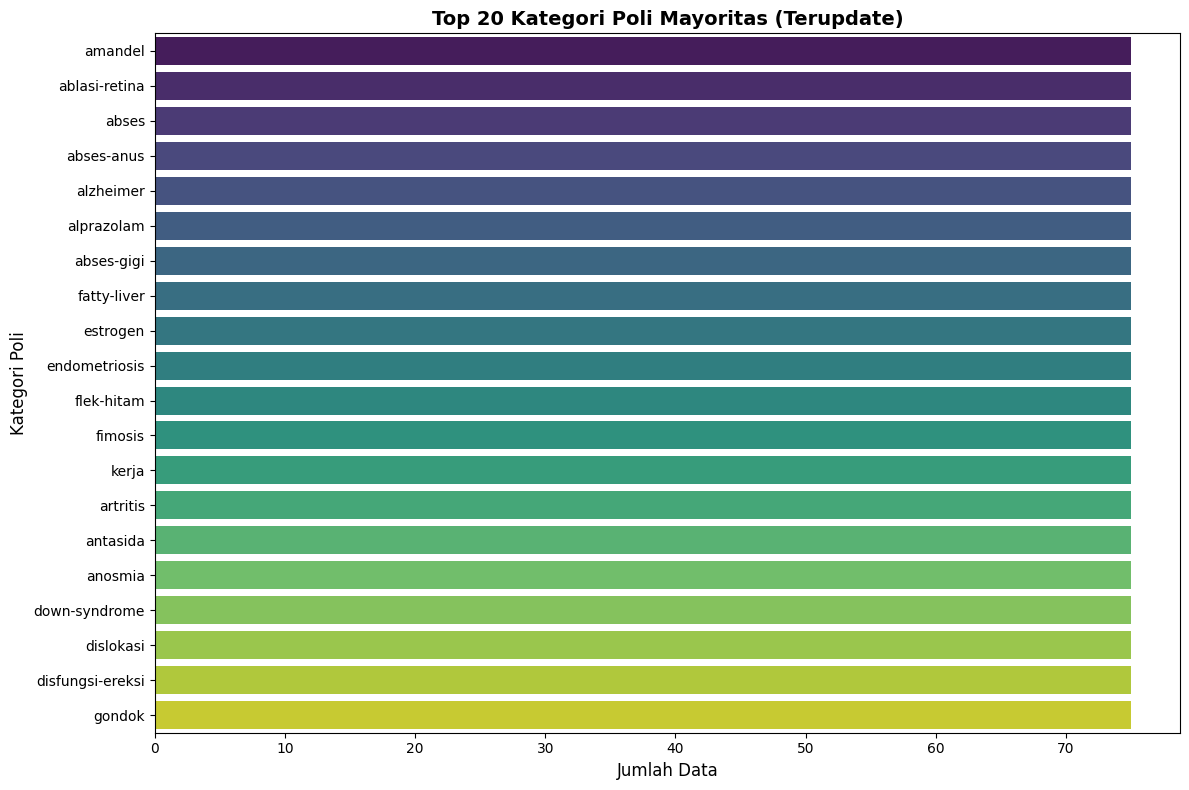

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_33568\660930341.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bottom_20.values, y=bottom_20.index, palette='magma')


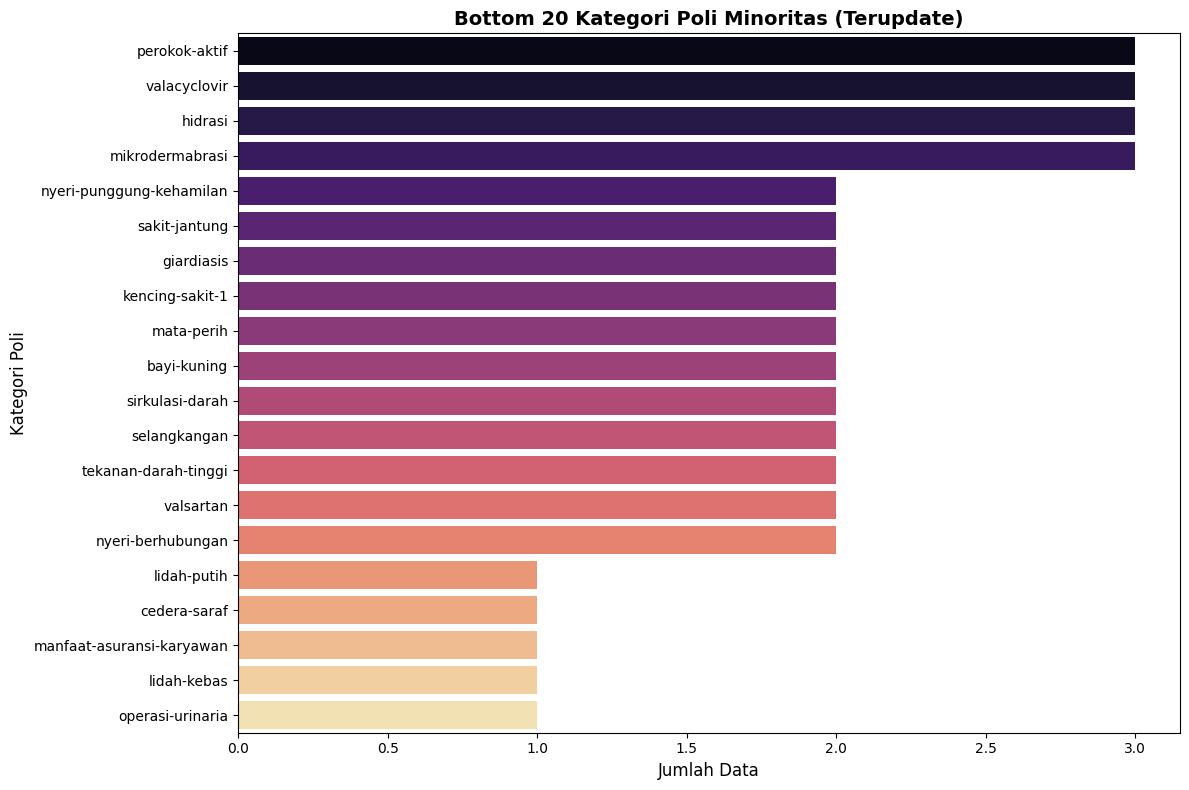

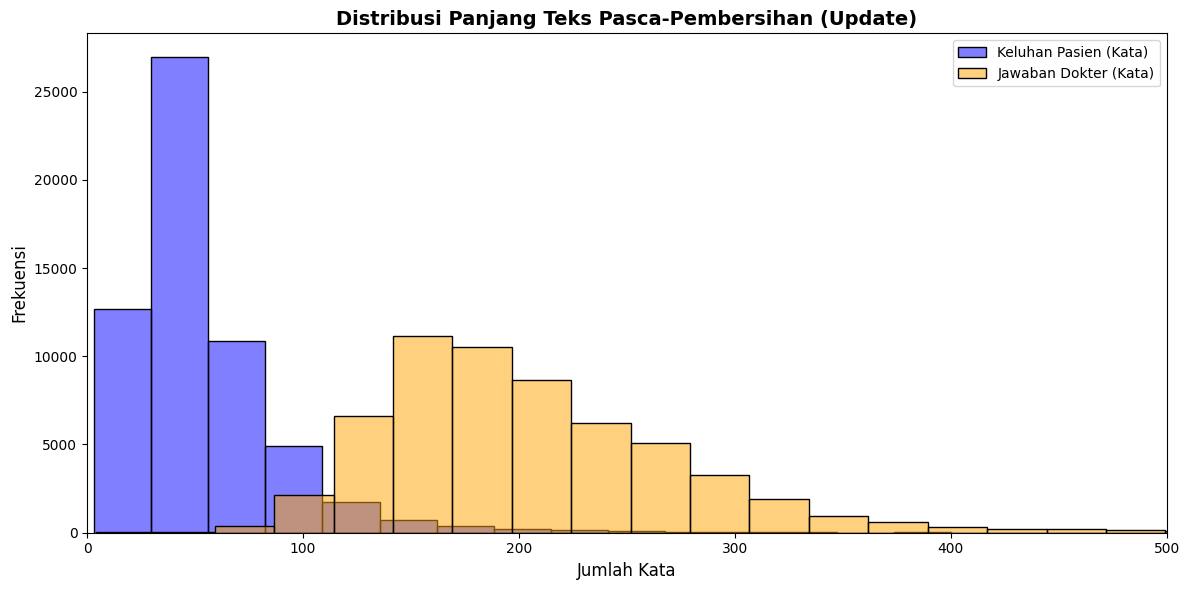


Statistik Kualitas Teks Baru:
        Len_Keluhan   Len_Jawaban
count  58907.000000  58907.000000
mean      53.128406    206.891405
std       38.601498     75.268320
min        3.000000      4.000000
25%       31.000000    156.000000
50%       44.000000    193.000000
75%       64.000000    244.000000
max     1327.000000   1380.000000


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# KONFIGURASI FILE
# ==========================================
file_final = 'dataset_nlp_medis_master_terupdate.csv' # File hasil integrasi terakhirmu

print("Memuat dataset final...")
if not os.path.exists(file_final):
    print(f"FATAL: File {file_final} tidak ditemukan. Pastikan eksekusi sebelumnya berhasil.")
else:
    df = pd.read_csv(file_final)
    print("=" * 50)
    print(f"Total Baris Data Saat Ini : {len(df)}")
    print(f"Total Kategori (Poli)     : {df['Poli_Tujuan'].nunique()}")
    print("=" * 50)
    
    # ------------------------------------------
    # PLOT 1: TOP 20 MAYORITAS
    # ------------------------------------------
    plt.figure(figsize=(12, 8))
    top_20 = df['Poli_Tujuan'].value_counts().head(20)
    sns.barplot(x=top_20.values, y=top_20.index, palette='viridis')
    plt.title('Top 20 Kategori Poli Mayoritas (Terupdate)', fontsize=14, fontweight='bold')
    plt.xlabel('Jumlah Data', fontsize=12)
    plt.ylabel('Kategori Poli', fontsize=12)
    plt.tight_layout()
    plt.show()

    # ------------------------------------------
    # PLOT 2: BOTTOM 20 MINORITAS (PEMBUKTIAN)
    # ------------------------------------------
    plt.figure(figsize=(12, 8))
    bottom_20 = df['Poli_Tujuan'].value_counts().tail(20)
    sns.barplot(x=bottom_20.values, y=bottom_20.index, palette='magma')
    plt.title('Bottom 20 Kategori Poli Minoritas (Terupdate)', fontsize=14, fontweight='bold')
    plt.xlabel('Jumlah Data', fontsize=12)
    plt.ylabel('Kategori Poli', fontsize=12)
    plt.tight_layout()
    plt.show()

    # ------------------------------------------
    # PLOT 3: DISTRIBUSI KUALITAS TEKS
    # ------------------------------------------
    df['Len_Keluhan'] = df['Keluhan'].astype(str).apply(lambda x: len(x.split()))
    df['Len_Jawaban'] = df['Jawaban_Dokter'].astype(str).apply(lambda x: len(x.split()))
    
    plt.figure(figsize=(12, 6))
    sns.histplot(df['Len_Keluhan'], bins=50, color='blue', alpha=0.5, label='Keluhan Pasien (Kata)')
    sns.histplot(df['Len_Jawaban'], bins=50, color='orange', alpha=0.5, label='Jawaban Dokter (Kata)')
    plt.title('Distribusi Panjang Teks Pasca-Pembersihan (Update)', fontsize=14, fontweight='bold')
    plt.xlabel('Jumlah Kata', fontsize=12)
    plt.ylabel('Frekuensi', fontsize=12)
    plt.xlim(0, 500) # Membatasi tampilan x-axis agar lebih jelas
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    print("\nStatistik Kualitas Teks Baru:")
    print(df[['Len_Keluhan', 'Len_Jawaban']].describe())

Membangun kanvas visualisasi untuk 1422 kategori poli...
[SUKSES] Gambar 'distribusi_poli_tujuan_terupdate.png' berhasil dicetak.




In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ==========================================
# KONFIGURASI FILE TERUPDATE
# ==========================================
file_final = 'dataset_nlp_medis_master_terupdate.csv'

try:
    df = pd.read_csv(file_final)
except FileNotFoundError:
    print(f"FATAL: {file_final} tidak ditemukan. Jalankan dulu skrip penggabungan sebelumnya.")
    exit()

# Hitung distribusi dan urutkan dari terkecil
vc = df['Poli_Tujuan'].value_counts().sort_values(ascending=True)
total_kelas = len(vc)

print(f"Membangun kanvas visualisasi untuk {total_kelas} kategori poli...")

# Buat figure dinamis (Tinggi menyesuaikan jumlah kelas)
fig, ax = plt.subplots(figsize=(14, max(10, total_kelas * 0.22)))

# ==========================================
# LOGIKA WARNA (METRIK KEBERHASILAN BALANCING)
# ==========================================
kondisi_1 = vc < 20
kondisi_2 = (vc >= 20) & (vc < 50)
kondisi_3 = (vc >= 50) & (vc < 75)
kondisi_4 = vc >= 75

# Hitung jumlah kelas per kategori secara otomatis
count_1 = kondisi_1.sum()
count_2 = kondisi_2.sum()
count_3 = kondisi_3.sum()
count_4 = kondisi_4.sum()

# Terapkan warna menggunakan numpy (Lebih efisien dari list comprehension)
colors = np.where(kondisi_1, '#E24B4A',
         np.where(kondisi_2, '#EF9F27',
         np.where(kondisi_3, '#378ADD', '#639922')))

# Plotting
ax.barh(vc.index, vc.values, color=colors, height=0.85)

ax.set_xlabel('Jumlah Sampel', fontsize=12)
ax.set_title(f'Distribusi Sampel per Poli Tujuan Pasca-Balancing ({total_kelas} Kelas)', fontsize=14, fontweight='bold', pad=12)
ax.tick_params(axis='y', labelsize=5.5)
ax.tick_params(axis='x', labelsize=10)

# ==========================================
# GARIS BATAS & LEGENDA
# ==========================================
# Garis batas target kita
garis_target = ax.axvline(x=30, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.axvline(x=75, color='gray', linestyle=':', linewidth=0.8, alpha=0.5)

# Legenda dinamis
legend_elements = [
    Patch(color='#E24B4A', label=f'< 20 sampel ({count_1} kelas) - Kritis/Habis Halaman'),
    Patch(color='#EF9F27', label=f'20–49 sampel ({count_2} kelas) - Mendekati Target'),
    Patch(color='#378ADD', label=f'50–74 sampel ({count_3} kelas) - Target Tercapai'),
    Patch(color='#639922', label=f'>= 75 sampel ({count_4} kelas) - Mayoritas Aman')
]

# Menggabungkan patch warna dengan garis vertikal di legenda
ax.legend(handles=legend_elements + [(garis_target)], 
          labels=[p._label for p in legend_elements] + ['Garis Target Minimum (50)'],
          loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig('distribusi_poli_tujuan_terupdate.png', dpi=150, bbox_inches='tight')
print("[SUKSES] Gambar 'distribusi_poli_tujuan_terupdate.png' berhasil dicetak.")
plt.show()

In [1]:
import pandas as pd

# 1. Muat dataset terakhirmu
file_target = 'dataset_nlp_medis_master_terupdate.csv' 
df = pd.read_csv(file_target)

# 2. Hitung distribusi (jumlah sampel per poli)
distribusi = df['Poli_Tujuan'].value_counts()

# ==========================================
# LOGIKA PENGHITUNGAN DATA < 30
# ==========================================
# Memfilter hanya poli yang jumlahnya di bawah 30
poli_under_30 = distribusi[distribusi < 30]

# Menghitung ADA BERAPA BANYAK kategori poli tersebut
jumlah_kategori = len(poli_under_30) # atau bisa pakai (distribusi < 30).sum()

# Menghitung TOTAL SELURUH BARIS DATA dari poli-poli yang kurang dari 30 tersebut
total_baris_data = poli_under_30.sum()

print("="*50)
print(f"HASIL ANALISIS KELAS MINORITAS (< 30 SAMPEL)")
print("="*50)
print(f"Total Kategori Poli     : {jumlah_kategori} kategori")
print(f"Total Baris Data Mentah : {total_baris_data} baris data")
print("="*50)

# Jika kamu ingin melihat daftar lengkap nama poli dan angkanya:
print("\n[Detail Poli & Jumlah Datanya]:")
print(poli_under_30)

HASIL ANALISIS KELAS MINORITAS (< 30 SAMPEL)
Total Kategori Poli     : 552 kategori
Total Baris Data Mentah : 6786 baris data

[Detail Poli & Jumlah Datanya]:
Poli_Tujuan
ekokardiografi               29
candesartan                  29
gagal-hati                   29
kaki-gajah                   29
efek-samping-obat            29
                             ..
lidah-putih                   1
cedera-saraf                  1
manfaat-asuransi-karyawan     1
lidah-kebas                   1
operasi-urinaria              1
Name: count, Length: 552, dtype: int64


In [ ]:
import pandas as pd
import os

# ==========================================
# KONFIGURASI FILE
# ==========================================
# Pastikan nama file ini persis dengan yang ada di Kaggle-mu
file_master = 'dataset_nlp_medis_master_terupdate.csv' 
file_ambeien = 'investigasi_mendalam_ambeien.csv'
file_lidah = 'investigasi_mendalam_lidah-putih.csv'

file_final_baru = 'dataset_nlp_medis_master_v2.csv' # Kita beri nama v2 agar ada backup

print("Memuat brankas data...")
# Cek eksistensi file
for f in [file_master, file_ambeien, file_lidah]:
    if not os.path.exists(f):
        print(f"FATAL: File {f} tidak ditemukan di direktori!")
        exit()

df_master = pd.read_csv(file_master)
df_amb = pd.read_csv(file_ambeien)
df_ldh = pd.read_csv(file_lidah)

# Gabungkan kedua file investigasi menjadi satu wadah "data segar"
df_segar = pd.concat([df_amb, df_ldh], ignore_index=True)

print(f"[INFO] Total Master Lama: {len(df_master)} baris")
print(f"[INFO] Total Data Segar (Ambeien & Lidah Putih): {len(df_segar)} baris")

# ==========================================
# TAHAP 1: IDENTIFIKASI TARGET PEMUSNAHAN
# ==========================================
kategori_diperbarui = df_segar['Poli_Tujuan'].unique()
print(f"\nMendeteksi kategori yang akan ditransplantasi: {list(kategori_diperbarui)}")

# ==========================================
# TAHAP 2: PEMUSNAHAN DATA CACAT LAMA
# ==========================================
# Cungkil dan buang data ambeien & lidah-putih versi lama dari master
df_master_bersih = df_master[~df_master['Poli_Tujuan'].isin(kategori_diperbarui)].copy()

data_lama_dibuang = len(df_master) - len(df_master_bersih)
print(f"  -> Mencungkil dan membuang {data_lama_dibuang} baris data cacat dari Master Lama.")

# ==========================================
# TAHAP 3: INJEKSI DATA SEGAR
# ==========================================
df_gabungan = pd.concat([df_master_bersih, df_segar], ignore_index=True)
print("  -> Menyuntikkan data investigasi segar ke dalam sistem...")

# ==========================================
# TAHAP 4: LAPISAN PERTAHANAN (CEK REDUNDANSI URL)
# ==========================================
total_sebelum_dedup = len(df_gabungan)
df_gabungan = df_gabungan.drop_duplicates(subset=['URL'])
total_setelah_dedup = len(df_gabungan)

redundansi_url = total_sebelum_dedup - total_setelah_dedup
if redundansi_url > 0:
    print(f"  -> Menemukan dan menghapus {redundansi_url} redundansi URL.")
else:
    print("  -> Tidak ada redundansi URL. Data aman.")

# ==========================================
# TAHAP 5: FINALISASI & SIMPAN
# ==========================================
df_gabungan.to_csv(file_final_baru, index=False)

print("\n" + "="*60)
print("🏆 INTEGRASI DATA TAHAP 2 SELESAI")
print("="*60)
print(f"Total Data Master Final : {len(df_gabungan)} baris.")
print(f"File Emas Tersimpan     : '{file_final_baru}'")
print("="*60)

In [1]:
import pandas as pd

# 1. Muat dataset terakhirmu
file_target = 'dataset_nlp_medis_master_v2.csv' 
df = pd.read_csv(file_target)

# 2. Hitung distribusi (jumlah sampel per poli)
distribusi = df['Poli_Tujuan'].value_counts()

# ==========================================
# LOGIKA PENGHITUNGAN DATA < 30
# ==========================================
# Memfilter hanya poli yang jumlahnya di bawah 30
poli_under_30 = distribusi[distribusi < 3]

# Menghitung ADA BERAPA BANYAK kategori poli tersebut
jumlah_kategori = len(poli_under_30) # atau bisa pakai (distribusi < 30).sum()

# Menghitung TOTAL SELURUH BARIS DATA dari poli-poli yang kurang dari 30 tersebut
total_baris_data = poli_under_30.sum()

print("="*50)
print(f"HASIL ANALISIS KELAS MINORITAS (< 30 SAMPEL)")
print("="*50)
print(f"Total Kategori Poli     : {jumlah_kategori} kategori")
print(f"Total Baris Data Mentah : {total_baris_data} baris data")
print("="*50)

# Jika kamu ingin melihat daftar lengkap nama poli dan angkanya:
print("\n[Detail Poli & Jumlah Datanya]:")
print(poli_under_30)

HASIL ANALISIS KELAS MINORITAS (< 30 SAMPEL)
Total Kategori Poli     : 16 kategori
Total Baris Data Mentah : 28 baris data

[Detail Poli & Jumlah Datanya]:
Poli_Tujuan
tekanan-darah-tinggi         2
mata-perih                   2
nyeri-punggung-kehamilan     2
nyeri-berhubungan            2
selangkangan                 2
sirkulasi-darah              2
sakit-jantung                2
kencing-sakit-1              2
lidah-putih                  2
bayi-kuning                  2
valsartan                    2
giardiasis                   2
operasi-urinaria             1
manfaat-asuransi-karyawan    1
lidah-kebas                  1
cedera-saraf                 1
Name: count, dtype: int64


In [4]:
import pandas as pd

# ==========================================
# KONFIGURASI FILE
# ==========================================
file_input = 'dataset_nlp_medis_master_v2.csv' 
file_output = 'dataset_nlp_medis_final_terprioritas.csv'

print("Memuat dataset untuk resolusi konflik URL...")
try:
    df = pd.read_csv(file_input)
except FileNotFoundError:
    print(f"FATAL: {file_input} tidak ditemukan.")
    exit()

total_awal = len(df)
print(f"Total data mentah: {total_awal} baris")

# ==========================================
# LOGIKA PRIORITAS MINORITAS & PENGURUTAN
# ==========================================
# 1. Hitung "kekayaan" tiap poli (jumlah sampel yang mereka miliki)
frekuensi_poli = df['Poli_Tujuan'].value_counts().to_dict()

# 2. Tempelkan angka kekayaan tersebut ke setiap baris data sebagai 'Bobot'
df['Bobot_Populasi'] = df['Poli_Tujuan'].map(frekuensi_poli)

# 3. Urutkan seluruh dataset berdasarkan Bobot_Populasi dari TERKECIL ke TERBESAR.
# Ini memastikan data minoritas berada di atas untuk dipertahankan saat deduplikasi.
df_sorted = df.sort_values(by='Bobot_Populasi', ascending=True)

# 4. Eksekusi Pemenggalan Duplikat (Mempertahankan kelas minoritas)
df_final = df_sorted.drop_duplicates(subset=['URL'], keep='first')

# 5. Bersihkan kolom bantuan agar dataset kembali rapi
df_final = df_final.drop(columns=['Bobot_Populasi'])

# 6. PERBAIKAN: Urutkan secara alfabetis berdasarkan nama Poli_Tujuan
# Ini akan membuat data mengelompok rapi sesuai dengan kategorinya masing-masing
df_final = df_final.sort_values(by='Poli_Tujuan', ascending=True).reset_index(drop=True)

total_akhir = len(df_final)
terselamatkan_ke_minoritas = total_awal - total_akhir

print("\n" + "="*60)
print("HASIL RESOLUSI KONFLIK & PENGURUTAN DATA")
print("="*60)
print(f"Total data setelah dibersihkan : {total_akhir} baris unik absolut.")
print(f"Total URL yang tumpang tindih  : {terselamatkan_ke_minoritas} URL.")
print("Semua data sekarang tersusun rapi secara berurutan berdasarkan nama poli.")
print("="*60)

df_final.to_csv(file_output, index=False)
print(f"[SUKSES] Dataset final berurutan tersimpan di: {file_output}")

Memuat dataset untuk resolusi konflik URL...
Total data mentah: 58910 baris

HASIL RESOLUSI KONFLIK & PENGURUTAN DATA
Total data setelah dibersihkan : 58910 baris unik absolut.
Total URL yang tumpang tindih  : 0 URL.
Semua data sekarang tersusun rapi secara berurutan berdasarkan nama poli.
[SUKSES] Dataset final berurutan tersimpan di: dataset_nlp_medis_final_terprioritas.csv


In [5]:
import pandas as pd
import os

# ==========================================
# KONFIGURASI FILE
# ==========================================
file_master = 'dataset_nlp_medis_final_terprioritas.csv' 
file_lidah = 'investigasi_mendalam_lidah-putih.csv'
file_output = 'dataset_nlp_medis_paksaan_lidah_putih.csv'

print("Memuat dataset untuk injeksi paksa...")
if not os.path.exists(file_master) or not os.path.exists(file_lidah):
    print("FATAL: File tidak ditemukan.")
    exit()

df_master = pd.read_csv(file_master)
df_ldh = pd.read_csv(file_lidah)

# ==========================================
# EKSEKUSI INJEKSI TANPA FILTER DEDUPLIKASI
# ==========================================
# 1. Cungkil dan hapus SEMUA data lidah-putih dari master saat ini 
# agar tidak terjadi bentrok dengan file investigasi
df_tanpa_lidah = df_master[df_master['Poli_Tujuan'] != 'lidah-putih'].copy()

# 2. Gabungkan master (yang sudah dibersihkan dari lidah-putih) dengan 5 baris file investigasi
# Kita TIDAK menggunakan drop_duplicates di sini, membiarkan kloningan masuk
df_final = pd.concat([df_tanpa_lidah, df_ldh], ignore_index=True)

# 3. Urutkan kembali secara alfabetis agar rapi sesuai kategori poli
df_final = df_final.sort_values(by='Poli_Tujuan', ascending=True).reset_index(drop=True)

# ==========================================
# PENYIMPANAN
# ==========================================
df_final.to_csv(file_output, index=False)

jumlah_lidah_putih = len(df_final[df_final['Poli_Tujuan'] == 'lidah-putih'])

print("\n" + "="*60)
print("HASIL INJEKSI PAKSA: LIDAH PUTIH")
print("="*60)
print(f"Total baris data 'lidah-putih' di file final : {jumlah_lidah_putih}")
print(f"Total seluruh dataset                        : {len(df_final)} baris")
print(f"File tersimpan di                            : {file_output}")
print("="*60)
print("Peringatan: Kamu sengaja memasukkan data duplikat murni ke dalam dataset pelatihanmu.")

Memuat dataset untuk injeksi paksa...

HASIL INJEKSI PAKSA: LIDAH PUTIH
Total baris data 'lidah-putih' di file final : 5
Total seluruh dataset                        : 58913 baris
File tersimpan di                            : dataset_nlp_medis_paksaan_lidah_putih.csv
Peringatan: Kamu sengaja memasukkan data duplikat murni ke dalam dataset pelatihanmu.


In [ ]:
import pandas as pd
import os

# ==========================================
# KONFIGURASI FILE FINAL
# ==========================================
# File terakhir hasil injeksi paksamu
file_final = 'dataset_nlp_medis_paksaan_lidah_putih.csv' 
TARGET_MINIMUM = 5

print(f"Memeriksa status kelas minoritas pada file: {file_final}...\n")

if not os.path.exists(file_final):
    print(f"FATAL: {file_final} tidak ditemukan.")
    exit()

df = pd.read_csv(file_final)

# Hitung distribusi sampel per poli
distribusi = df['Poli_Tujuan'].value_counts()

# Filter poli yang jumlah datanya masih di bawah target (50)
poli_minoritas = distribusi[distribusi < TARGET_MINIMUM]

# ==========================================
# LAPORAN EVALUASI
# ==========================================
print("="*50)
print(f"LAPORAN KELAS MINORITAS (< {TARGET_MINIMUM} SAMPEL)")
print("="*50)

if len(poli_minoritas) == 0:
    print("LUAR BIASA: Tidak ada lagi kelas minoritas. Semua poli mencapai target!")
else:
    print(f"Total Poli Minoritas tersisa  : {len(poli_minoritas)} kategori")
    print(f"Total Baris Data di Minoritas : {poli_minoritas.sum()} baris\n")
    print("[Detail Poli Minoritas dan Jumlahnya]:")
    
    # Menampilkan daftar poli minoritas secara rapi
    for poli, jumlah in poli_minoritas.items():
        print(f" - {poli.ljust(30)} : {jumlah} sampel")

print("="*50)
print(f"Total Keseluruhan Baris Data  : {len(df)}")
print(f"Total Keseluruhan Kategori    : {df['Poli_Tujuan'].nunique()}")
print("="*50)

Memeriksa status kelas minoritas pada file: dataset_nlp_medis_paksaan_lidah_putih.csv...

LAPORAN KELAS MINORITAS (< 5 SAMPEL)
Total Poli Minoritas tersisa  : 56 kategori
Total Baris Data di Minoritas : 184 baris

[Detail Poli Minoritas dan Jumlahnya]:
 - trombofilia                    : 4 sampel
 - bintik-kulit                   : 4 sampel
 - pemfigoid-bulosa               : 4 sampel
 - solar-keratosis                : 4 sampel
 - makanan                        : 4 sampel
 - gastroschisis                  : 4 sampel
 - sistoskopi                     : 4 sampel
 - ruam                           : 4 sampel
 - vaksin-influenza               : 4 sampel
 - obat-cacing                    : 4 sampel
 - kesehatan-jantung              : 4 sampel
 - mupirocin                      : 4 sampel
 - cimetidine                     : 4 sampel
 - kulit-kelamin                  : 4 sampel
 - nyeri-tangan                   : 4 sampel
 - kanker-sarkoma-ewing           : 4 sampel
 - polip-gigi              

: 